# Running the repository

A walk-through of the pipeline of *Data Augmentation in Property Graphs using agentic AI*:

1. **Task sets**: what a task is and where the task files are;
2. **Strategy A** (the LLM alone) and **3. Strategy B** (the search agent), run here offline with a mock model;
4. **Real runs** on Ollama Cloud (commands; off by default);
5. **Scoring**: from raw answers to F1, precision and recall;
6. **Figures and tables** of the paper.

Every cell runs without an API key and makes no paid call. The demo runs write to a temporary folder, never to
`results/`. Setup and the full command list are in `README.md`.

In [1]:
import json, os, re, subprocess, sys, tempfile
from pathlib import Path

import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                                    # configs use paths relative to the repository root
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks")]
BIN = Path(sys.executable).parent                 # venv/bin: the `tasks`, `strategy-a` and `strategy-b` commands
DEMO = Path(tempfile.mkdtemp(prefix="agentaug_demo_"))
pd.set_option("display.max_colwidth", 120)

RUN_LIVE = False   # True runs the cells of section 4, which call Ollama Cloud (needs OLLAMA_API_KEY in .env)

def sh(*args, last=None):
    """Run a command of the repository and print its output (only the last lines when `last` is set)."""
    out = subprocess.run([str(a) for a in args], capture_output=True, text=True, cwd=ROOT)
    lines = (out.stdout + out.stderr).strip().splitlines()
    print("\n".join(lines[-last:] if last else lines))
    if out.returncode:
        print(f"(exit code {out.returncode})")

from dotenv import dotenv_values
env = dotenv_values(ROOT / ".env") if (ROOT / ".env").exists() else {}
print("repository:", ROOT.name)
print(".env found:", bool(env))
for name in ("OLLAMA_API_KEY", "NEO4J_URI"):          # whether they are set, never their values
    print(f"  {name} set:", bool(env.get(name) or os.environ.get(name)))

repository: agentaugmentation
.env found: True
  OLLAMA_API_KEY set: True
  NEO4J_URI set: True


## 1. Task sets

A task is one node of the graph, a set **G** of given properties (from the node, and with context also from its
neighbours) and one hidden property **H** that the model must recover. The task sets are in `tasks/`:

- `tasks.csv`: what the strategies read;
- `ground_truth.csv`: the hidden values, read only by the evaluation (the strategies refuse to open it);
- `manifest.json` and `intermediate/`: how the set was built (snapshot, centrality, context, popularity).

The airports set with context has 243 tasks; the paper evaluates the 108 of them listed in
`data/new-diff-airports_ressampled.csv`, resampled by difficulty.

In [2]:
from evaluation import taskset as E

tasks = E.load_tasks(ROOT / "tasks/airports/v5_ctx/tasks.csv")
truth = E.load_ground_truth(ROOT / "tasks/airports/v5_ctx/ground_truth.csv")
selected = pd.read_csv(ROOT / "data/new-diff-airports_ressampled.csv").rename(columns={"taskID": "task_id"})
print(f"{len(tasks)} tasks in airports v5_ctx, {len(selected)} in the paper's evaluation, "
      f"{tasks.task_id.isin(selected.task_id).sum()} of them found")
tasks[["task_id", "node_id", "size_G", "node_stratum", "H_stratum", "G_stratum"]].head()

243 tasks in airports v5_ctx, 108 in the paper's evaluation, 108 of them found


,task_id,node_id,size_G,node_stratum,H_stratum,G_stratum
0,c3932857c60d6ddc,LIBG,1,low,low,low
1,a60e21be305e884d,LFOV,1,low,low,low
2,5ea9d4094994e820,LFQA,1,low,low,low
3,70b7ae2748e2d635,LFRZ,1,low,low,mid
4,7df1a5e39466884a,LSMF,1,low,low,mid


In [3]:
t = tasks.iloc[0]
print("node:", t.node_id)
print("G (given):")
for g in t.G_list:
    print(f"  {g['path']}.{g['property_name']} = {g['value']!r}")
print("H (hidden):", [h["prop_key"] for h in t.H_list])
print("ground truth:", {h["prop_key"]: truth[(t.task_id, h["prop_key"])] for h in t.H_list})

node: LIBG
G (given):
  Airport-[OF]->City-[IN]->Country.cpi = 110.62
H (hidden): ['Airport.commercial_flights']
ground truth: {'Airport.commercial_flights': 280}


A new task set is built from Neo4j (read only) with `tasks build --config configs/airports_v5_ctx.yaml`; it writes
both the context-on set and the matched context-off set (`tasks/airports/v5_noctx`). Task sets are never overwritten.

## 2. Strategy A: the LLM alone

A Strategy A config names the task set, the prompt templates (`templates/figure2/`: compact, zero-shot, few-shot,
with and without chain of thought), the models and the output folder. Here a demo config uses the **mock** model,
which answers every prompt with an empty CSV (an abstention), so the whole run is offline.

In [4]:
demo_a = {
    "inputs": {"tasks": "tasks/airports/v5_ctx/tasks.csv", "examples": "data/examples/airports_v5.json",
               "property_notes": "data/property_notes/airports.yaml"},
    "runs_per_task": 3,
    "pfe_tokenizer": "simple",                       # the real configs use cl100k_base (downloaded once)
    "output_dir": str(DEMO / "strategy_a"),
    "templates": [{"id": "zero", "file": "templates/figure2/zero.v2.txt", "output": "csv"},
                  {"id": "few", "file": "templates/figure2/few.v2.txt", "output": "csv", "n_examples": [1]}],
    "model_defaults": {"params": {"temperature": 0.7, "max_tokens": 256}, "max_concurrency": 1},
    "models": [{"id": "mock-model", "provider": "mock", "tokenizer": "simple",
                "options": {"text": "property,value\n"}}],
}
CFG_A = DEMO / "strategy_a.yaml"
CFG_A.write_text(yaml.safe_dump(demo_a, sort_keys=False))
sh(BIN / "strategy-a", "render", "--config", CFG_A, "--limit", "1", "--variant", "zero")   # the prompt, no call

# task c3932857c60d6ddc  variant zero  model mock-model

=== SYSTEM ===
# Identity

You are an assistant that enrichs entities from a database by identifying the corresponding real-world entity and adding values for specific properties. These attributes will be transformed into property:value pairs in a property-graph database.

# Instructions
1. From the input node passed by the user (property:value pairs), infer the most likely real-world entity and its entity class (Person, Organization, Location, Product, Country). The entity can be either nodes or relationship between two real-world entities.
2. Find trustworthy and recent values for the following properties of this entity: commercial_flights. If you are not confident about the values, do not include them.
3. Do not include any other property and do not include information that already exists in the input.
Notes on some properties:
- commercial_flights: annual number of commercial flights at the airport (Eurostat airport statistic

In [5]:
sh(BIN / "strategy-a", "run", "--config", CFG_A, "--limit", "3")
sh(BIN / "strategy-a", "run", "--config", CFG_A, "--limit", "3")   # resumable: the finished runs are skipped
res_a = pd.read_csv(DEMO / "strategy_a/results.csv")
res_a[["task_id", "variant", "model", "run_index", "status", "predictions", "tokens_in", "tokens_out"]]

18 runs planned, 0 already in results.csv, 18 to do
done: {'ok': 18}


18 runs planned, 18 already in results.csv, 0 to do
done: {}


,task_id,variant,model,run_index,status,predictions,tokens_in,tokens_out
0,c3932857c60d6ddc,zero,mock-model,1,ok,"{""Airport.commercial_flights"": null}",210,1
1,c3932857c60d6ddc,zero,mock-model,2,ok,"{""Airport.commercial_flights"": null}",210,1
2,c3932857c60d6ddc,zero,mock-model,3,ok,"{""Airport.commercial_flights"": null}",210,1
3,a60e21be305e884d,zero,mock-model,1,ok,"{""Airport.commercial_flights"": null}",210,1
4,a60e21be305e884d,zero,mock-model,2,ok,"{""Airport.commercial_flights"": null}",210,1
5,a60e21be305e884d,zero,mock-model,3,ok,"{""Airport.commercial_flights"": null}",210,1
6,5ea9d4094994e820,zero,mock-model,1,ok,"{""Airport.commercial_flights"": null}",210,1
7,5ea9d4094994e820,zero,mock-model,2,ok,"{""Airport.commercial_flights"": null}",210,1
8,5ea9d4094994e820,zero,mock-model,3,ok,"{""Airport.commercial_flights"": null}",210,1
9,c3932857c60d6ddc,few_1,mock-model,1,ok,"{""Airport.commercial_flights"": null}",225,1


Each run is one row of `results.csv` (the parsed answer per hidden property) and one record of `runs.jsonl` (the
full prompts, raw responses, tokens, energy and timings). The response cache (`cache/`) means a finished
configuration is never paid for twice.

## 3. Strategy B: the search agent

Two LLM calls per run: the **plan** identifies the entity and writes up to 3 web queries; the **synthesis** answers
from the retrieved evidence, citing it. Here the model and the search are both mocks, driven from Python with the
same runner the `strategy-b` command uses.

In [6]:
from llmcore.providers.mock import MockProvider
from strategy_b.config import load_config as load_b
from strategy_b.runner import Runner as RunnerB
from strategy_b.search import MockSearch

demo_b = {
    "inputs": {"tasks": "tasks/airports/v5_ctx/tasks.csv", "property_notes": "data/property_notes/airports.yaml"},
    "runs_per_task": 1, "max_subqueries": 3, "results_per_query": 3, "pfe_tokenizer": "simple",
    "output_dir": str(DEMO / "strategy_b"),
    "search": {"tool": "mock"},
    "blocked_domains": ["github.com/felipeVsc"],      # the repository that holds the ground truth
    "variants": [{"id": "search_evidence", "plan": "prompts/agent/plan.v2.txt",
                  "synthesize": "prompts/agent/synth.v2.txt"}],
    "models": [{"id": "mock-model", "provider": "mock", "tokenizer": "simple",
                "params": {"temperature": 0.7, "max_tokens": 256}, "max_concurrency": 1}],
}
CFG_B = DEMO / "strategy_b.yaml"
CFG_B.write_text(yaml.safe_dump(demo_b, sort_keys=False))

def mock_llm(request):
    text = request.messages[-1]["content"]
    if "Write at most" in text:                       # the plan call
        return json.dumps({"entity": "unknown", "queries": [{"id": "q1", "query": "airport ICAO code", "targets": []}]})
    # the synthesis call: answer every asked property with null (an abstention), in the requested format
    labels = re.findall(r'"([^"]+)": \{"value": "<value or null>"', text)
    return json.dumps({"predictions": {label: {"value": None, "unit": None, "sources": []} for label in labels}})

def mock_search(query):
    return [{"url": "https://example.org/airport", "title": "An airport", "content": "Some text about an airport.",
             "score": 0.9}]

cfg_b = load_b(CFG_B)
runner_b = RunnerB(cfg_b, limit=2, providers={"mock-model": MockProvider(cfg_b.models[0], responder=mock_llm)},
                   search_tool=MockSearch({}, responder=mock_search), log=print)
runner_b.run()
pd.read_csv(DEMO / "strategy_b/results.csv")[["task_id", "variant", "status", "predictions", "llm_calls", "search_calls"]]

2 runs planned, 2 to do
done: {'ok': 2}; search: {'calls': 3, 'cache_hits': 1, 'failures': 0, 'credits': 0.0, 'budget_refused': 0, 'rate_limit_waits': 0, 'rate_limit_wait_s': 0.0}


,task_id,variant,status,predictions,llm_calls,search_calls
0,a60e21be305e884d,search_evidence,ok,"{""Airport.commercial_flights"": null}",2,2
1,c3932857c60d6ddc,search_evidence,ok,"{""Airport.commercial_flights"": null}",2,2


In [7]:
run = json.loads((DEMO / "strategy_b/runs.jsonl").read_text().splitlines()[0])
print("fields logged per run:", sorted(run))

fields logged per run: ['calls', 'effort', 'evidence_passed', 'evidence_urls', 'label_map', 'model', 'plan_entity', 'plan_parsed', 'predictions', 'queries', 'results', 'retrieval_shared_with_run', 'run_index', 'status', 'task_id', 'usage', 'validation_events', 'variant']


## 4. Real runs on Ollama Cloud

The paper's configs are in `configs/` (`strategy_a_v5_ctx.yaml`, `strategy_b_v5_ctx.yaml`, the football and DOLAP
ones). They read the key from `OLLAMA_API_KEY` in `.env`. Useful steps, from the repository root:

```bash
venv/bin/strategy-a check    --config configs/strategy_a_v5_ctx.yaml                 # keys, models, templates
venv/bin/strategy-a estimate --config configs/strategy_a_v5_ctx.yaml --pending       # calls, tokens and cost left
venv/bin/strategy-a run      --config configs/strategy_a_v5_ctx.yaml --models cloud-gemma4-31b
venv/bin/strategy-b run      --config configs/strategy_b_v5_ctx.yaml --models cloud-gemma4-31b
venv/bin/strategy-b replay   --config configs/strategy_b_v5_ctx_memory.yaml \
    --source-dir results/airports/v5_ctx/strategy_b --source-variant search_evidence   # B + memory, no new search
```

The paper's runs are complete, so `run` on these configs finds every run already done and makes no call. A new
experiment needs its own `output_dir`. Strategy B costs about $0.015 per web search; keep the configs' pacing
(30 s between searches) and run one model at a time per key.

In [8]:
if RUN_LIVE:
    sh(BIN / "strategy-a", "check", "--config", "configs/strategy_a_v5_ctx.yaml", "--models", "cloud-gemma4-31b")
else:
    print("RUN_LIVE is False: no call to Ollama Cloud")

RUN_LIVE is False: no call to Ollama Cloud


## 5. Scoring

Each hidden property gets one outcome, on the answer voted over the runs (text: most frequent value; numbers: mean;
abstained only if every run abstains):

- **abstained**: no value, null or "unknown";
- **correct**: within the tolerance of `evaluation.dolap.matches_standard` (text overlap ≥ 0.75 both ways, numbers
  within 25%, coordinates within 10 km);
- **wrong**: otherwise.

With c correct, w wrong and a abstained: **precision = c / (c + w)**, **recall = c / (c + w + a)**,
**F1 = 2c / (2c + 2w + a)** (the paper's accuracy) and **F1 ign = 2c / (2c + w)** (abstentions ignored).

Scoring the raw answers of one configuration reproduces the shared scored file exactly:

In [9]:
raw = E.load_results(ROOT / "results/airports/v5_ctx/strategy_a")
raw = raw[(raw.model == "cloud-gemma4-31b") & (raw.variant == "zero") & (raw.status == "ok")]
scored = E.score_voted(raw, tasks, truth)

shared = pd.read_csv(ROOT / "results/airports/v5_ctx/scored/scored_voted.csv", low_memory=False)
same = scored.merge(shared[(shared.strategy == "A") & (shared.model == "cloud-gemma4-31b") & (shared.variant == "zero")],
                    on=["task_id", "prop_key"], suffixes=("", "_shared"))
print(f"{len(scored)} properties scored; identical outcome in the shared file: {(same.outcome == same.outcome_shared).mean():.0%}")
{k: round(v, 3) if isinstance(v, float) else v for k, v in E.metrics(scored).items()}

243 properties scored; identical outcome in the shared file: 100%


{'properties': 243,
 'correct': 30,
 'wrong': 70,
 'abstained': 143,
 'precision': 0.3,
 'recall': 0.123,
 'f1': 0.175,
 'abstention_rate': 0.588,
 'error_rate': 0.288,
 'published_accuracy': 0.3,
 'published_f1': 0.462}

`results/<dataset>/<set>/scored/scored_voted.csv` holds these rows for every strategy, prompt, model and task
(written by `notebooks/build_metrics_both_notebook.py` for airports and `scripts/football_idmix_scored.py` for
football). The paper's numbers on the 108 tasks, pooled over the models:

In [10]:
v = shared[shared.task_id.isin(selected.task_id)].copy()
v["approach"] = v.variant.map({"search_evidence": "B search", "search_memory": "B search + memory"}).fillna("A, all 9 prompts")
pooled = E.metrics_by(v, ["approach"]).set_index("approach")
pooled["f1_ign"] = pooled.published_f1
pooled[["properties", "correct", "wrong", "abstained", "f1", "precision", "recall", "f1_ign"]].round(3)

,properties,correct,wrong,abstained,f1,precision,recall,f1_ign
approach,,,,,,,,
"A, all 9 prompts",4860,908,2064,1888,0.232,0.306,0.187,0.468
B search,540,127,170,243,0.303,0.428,0.235,0.599
B search + memory,540,132,222,186,0.295,0.373,0.244,0.543


In [11]:
per_model = E.metrics_by(v, ["model", "approach"]).pivot(index="model", columns="approach", values="f1")
per_model.round(3)

approach,"A, all 9 prompts",B search,B search + memory
model,,,
cloud-deepseek-v4.1-flash,0.238,0.182,0.253
cloud-gemma4-31b,0.235,0.212,0.218
cloud-gpt-oss-120b,0.247,0.419,0.411
cloud-gpt-oss-20b,0.201,0.324,0.301
cloud-mistral-large-3,0.239,0.354,0.284


## 6. Figures and tables of the paper

Each script reads the scored files and writes PNG and PDF figures, CSV tables and a `facts.json` with every number
quoted in the text:

| Script | Output |
|---|---|
| `notebooks/resampled_figures.py` | airports, 108 tasks: accuracy, energy, tokens, difficulty (`figures/paper_reports/airports_resampled/`) |
| `notebooks/resampled_dolap_replica.py` | the DOLAP 2026 figures redrawn with the new data (same folder, `dolap_*`) |
| `notebooks/make_lessons_learned_tex.py` | `docs/paper_lessons_learned_resampled.tex`, the Lessons learned section |
| `notebooks/coauthor_figures.py` | airports and football A/B figures (`figures/paper_reports/coauthor/`) |
| `notebooks/build_paper_reports_notebook.py` | the football and both-datasets report notebooks |

In [12]:
sh(sys.executable, "notebooks/resampled_figures.py", last=1)
out = ROOT / "notebooks/figures/paper_reports/airports_resampled"
print(sorted(p.name for p in out.glob("*.png")))

['accuracy_by_approach.pdf', 'accuracy_by_approach.png', 'accuracy_vs_difficulty_bins.pdf', 'accuracy_vs_difficulty_bins.png', 'accuracy_vs_global_difficulty.pdf', 'accuracy_vs_global_difficulty.png', 'accuracy_vs_strata.pdf', 'accuracy_vs_strata.png', 'dolap_facts.json', 'dolap_fig1_energy_by_model.pdf', 'dolap_fig1_energy_by_model.png', 'dolap_fig2_energy_by_prompt.pdf', 'dolap_fig2_energy_by_prompt.png', 'dolap_fig3_accuracy_vs_difficulty.pdf', 'dolap_fig3_accuracy_vs_difficulty.png', 'dolap_fig4_accuracy_vs_effort.pdf', 'dolap_fig4_accuracy_vs_effort.png', 'energy.pdf', 'energy.png', 'f1_precision_abstention.pdf', 'f1_precision_abstention.png', 'facts.json', 'outcomes_by_approach.pdf', 'outcomes_by_approach.png', 'recall_by_property.pdf', 'recall_by_property.png', 'strategy_a_prompts.pdf', 'strategy_a_prompts.png', 'tables', 'token_amplification.pdf', 'token_amplification.png', 'tokens.pdf', 'tokens.png', 'where_models_are_right.pdf', 'where_models_are_right.png']
['accuracy_by_app

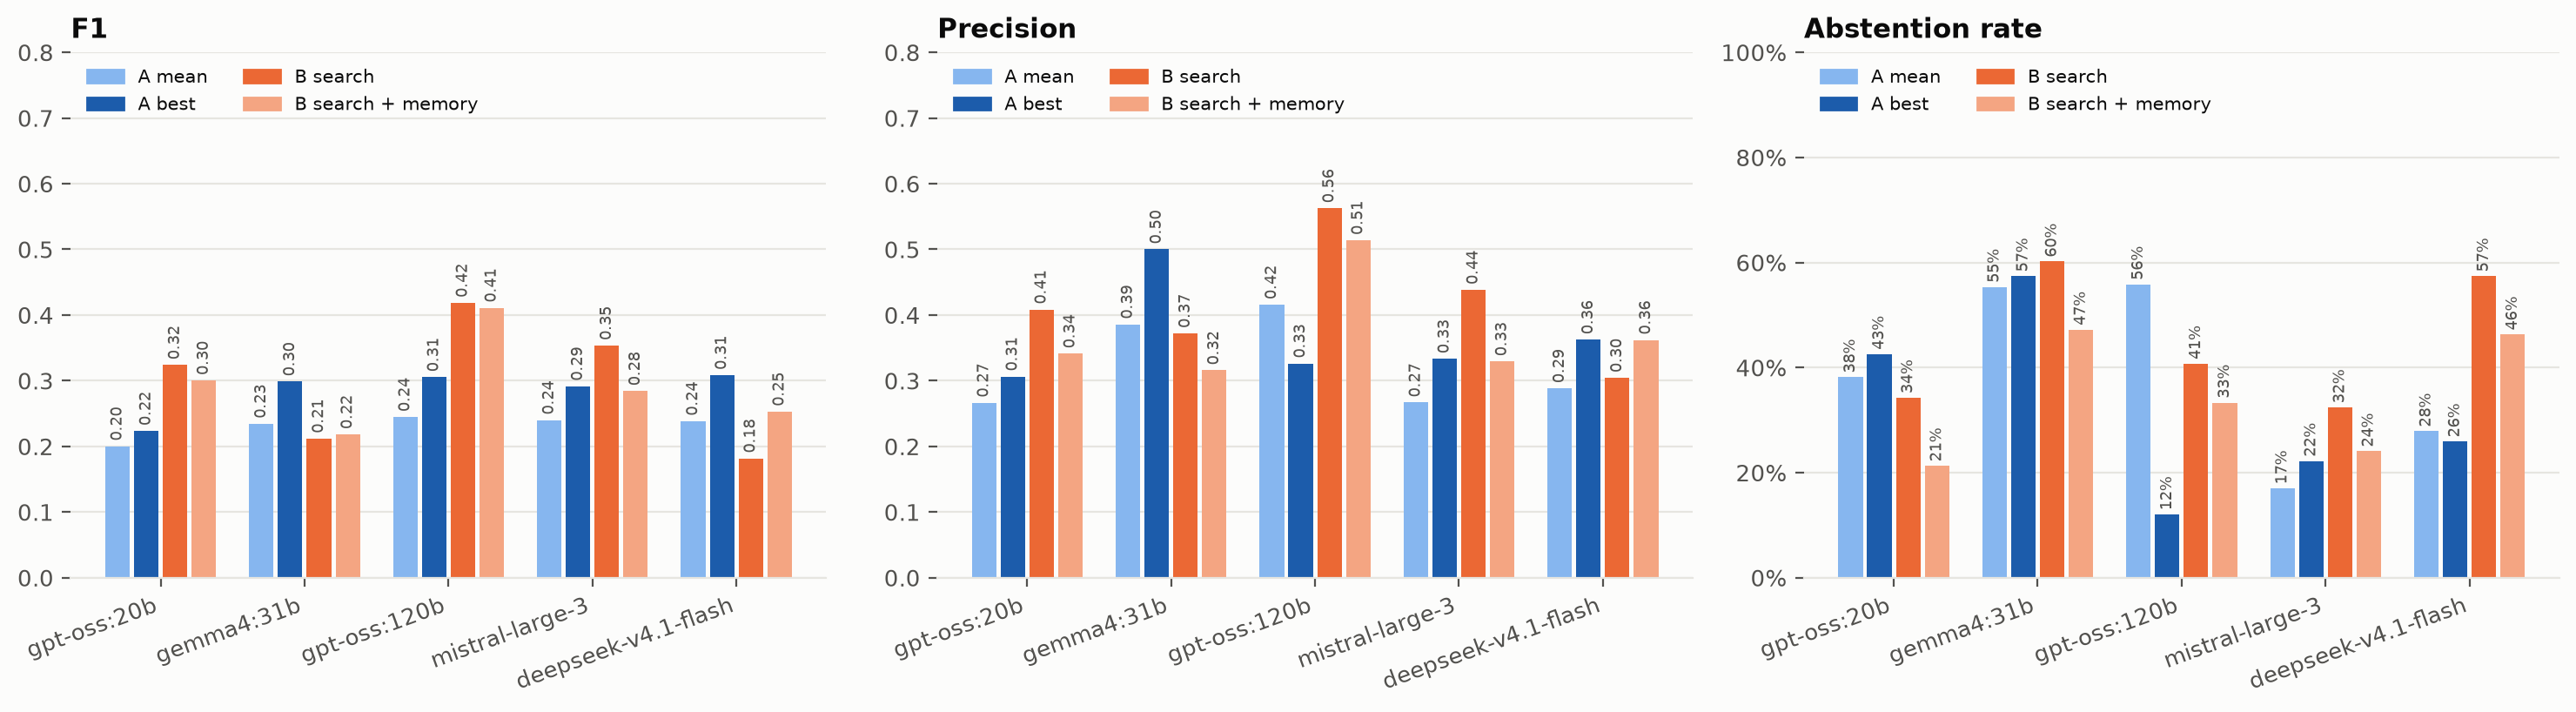

In [13]:
from IPython.display import Image
Image(filename=str(out / "f1_precision_abstention.png"), width=900)

In [14]:
facts = json.loads((out / "facts.json").read_text())
print(json.dumps(facts["best_prompt"], indent=1))

{
 "gpt-oss:20b": "3-shot + CoT",
 "gemma4:31b": "zero-shot + CoT",
 "gpt-oss:120b": "compact",
 "mistral-large-3": "3-shot + CoT",
 "deepseek-v4.1-flash": "5-shot + CoT"
}


## Where things are

| What | Where |
|---|---|
| Task sets | `tasks/<dataset>/<set>/` |
| Raw runs | `results/<dataset>/<set>/strategy_{a,b,b_memory}/results.csv` (the full logs `runs.jsonl` are not in git) |
| Scored rows | `results/<dataset>/<set>/scored/scored_voted.csv` |
| Energy and effort per run | `results/energy_effort/runs.csv` |
| Figures and tables | `notebooks/figures/paper_reports/` |
| Code | `src/taskdef`, `src/strategy_a`, `src/strategy_b`, `src/evaluation`, `src/llmcore` |